# Subscription CMO lab: Waterfall and Distributed campaign budgeting

This notebook applies the two frameworks in [Optimization models in digital advertising](https://mobiledevmemo.com/optimization-models-in-digital-advertising/) to the synthetic subscription cohorts:

1. **Waterfall budgeting — primary ROAS constraint:** maximize scalable channel spend until the **next marginal dollar** reaches the ROAS threshold.
2. **Distributed budgeting — primary budget constraint:** allocate a fixed budget for maximum portfolio ROAS while every active channel meets the channel-level ROAS threshold.

The CMO uses 180-day cohort revenue, not same-day conversion value. Theseus turns retention and monetization curves into revenue by cohort; empirical spend–revenue response curves then represent diminishing returns as campaign scale expands.

All values are deterministic synthetic assumptions. The notebook demonstrates the decision mechanics, not expected market performance.

### Start here and related reading

- [Theseus API introduction and walkthrough](../../Theseus_Walkthrough.ipynb)
- [Optimization models in digital advertising](https://mobiledevmemo.com/optimization-models-in-digital-advertising/)
- [Building a marketing P&L using LTV and ROAS](https://mobiledevmemo.com/ltv-roas-marketing-p-and-l/)

In [1]:
from itertools import combinations
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.figure import Figure
from scipy.interpolate import PchipInterpolator
from scipy.optimize import minimize

import theseus_growth as tg

%matplotlib inline
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "pyproject.toml").exists())
DATA = ROOT / "examples" / "data" / "subscription"

curves = pd.read_csv(DATA / "curves.csv")
curve_assumptions = pd.read_csv(DATA / "curve_assumptions.csv").set_index("curve_id")
response_assumptions = pd.read_csv(
    DATA / "campaign_response_assumptions.csv"
).set_index("channel")
response_assumptions["cac"] = response_assumptions["curve_id"].map(
    curve_assumptions["cac"]
)

REVENUE_WINDOW = 180
ROAS_TARGET = 1.20
DISTRIBUTED_BUDGET = 60000.0
HISTORICAL_POINTS = 21

display(response_assumptions)
print(f"Optimization window: {REVENUE_WINDOW} days")
print(f"Channel ROAS threshold: {ROAS_TARGET:.2f}×")
print(f"Distributed weekly budget: ${DISTRIBUTED_BUDGET:,.0f}")

,curve_id,max_weekly_spend,min_active_spend,saturation_subscribers,cac
channel,,,,,
paid_search,sub_paid_search,80000,5000,1700,58
affiliate,sub_affiliate,50000,5000,1100,48
podcast,sub_podcast_actual,90000,5000,1500,58
display,sub_display_actual,50000,5000,1200,52
ctv,sub_ctv_actual,60000,5000,900,105


Optimization window: 180 days
Channel ROAS threshold: 1.20×
Distributed weekly budget: $60,000


## Construct historical spend–revenue curves from cohorts

At low spend, acquired subscribers scale almost linearly. As spend expands, inventory is exhausted and the next dollar reaches lower-propensity audiences. The synthetic response assumption is:

`effective subscribers = capacity × (1 − exp(−spend / (CAC × capacity)))`

We sample that relationship at 21 historical spend levels per channel. Each sample becomes a canonical Theseus cohort using the channel's measured retention and monetization curve. The optimizer will use only the resulting spend–revenue points—not the generating equation.

This separates two questions:

- **Cohort value:** how much does an acquired subscriber generate over 180 days?
- **Campaign scalability:** how many incremental subscribers can the next dollar acquire at this spend level?

,cohort_id,channel,weekly_spend,revenue_180d,average_roas
0,paid_search-response-00,paid_search,0.000,0.000,NaN
1,paid_search-response-01,paid_search,"4,000.000","5,484.748",1.371
2,paid_search-response-02,paid_search,"8,000.000","10,751.443",1.344
3,paid_search-response-03,paid_search,"12,000.000","15,808.756",1.317
21,affiliate-response-00,affiliate,0.000,0.000,NaN
22,affiliate-response-01,affiliate,"2,500.000","3,663.745",1.465
23,affiliate-response-02,affiliate,"5,000.000","7,158.060",1.432
24,affiliate-response-03,affiliate,"7,500.000","10,490.780",1.399
42,podcast-response-00,podcast,0.000,0.000,NaN
43,podcast-response-01,podcast,"4,500.000","7,009.183",1.558


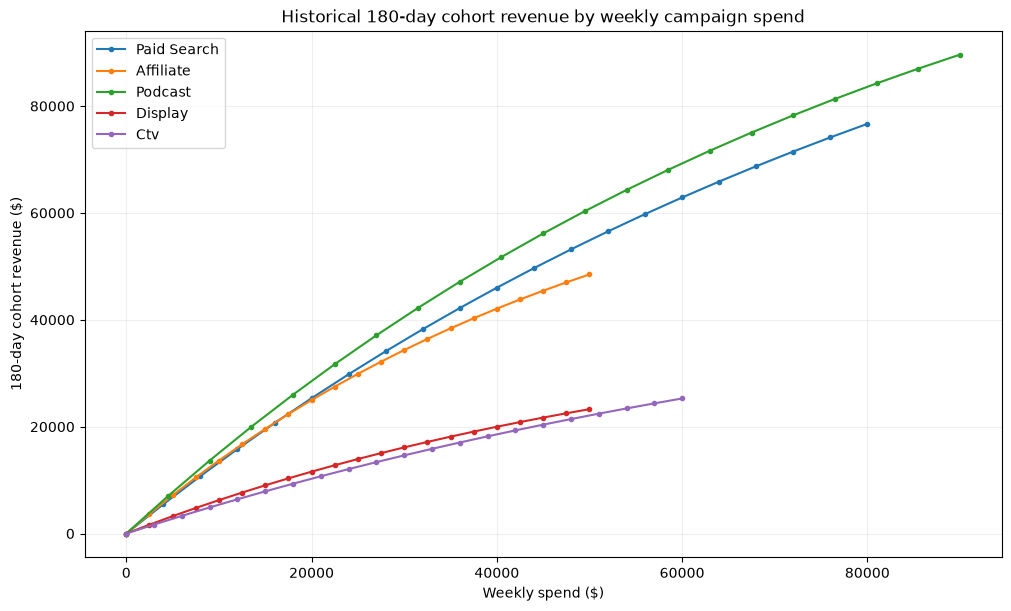

In [2]:
history_cohorts, history_spend = [], []
for channel, spec in response_assumptions.iterrows():
    spend_levels = np.linspace(0, spec["max_weekly_spend"], HISTORICAL_POINTS)
    for point, spend in enumerate(spend_levels):
        effective_subscribers = spec["saturation_subscribers"] * (
            1 - np.exp(
                -spend / (spec["cac"] * spec["saturation_subscribers"])
            )
        )
        cohort_id = f"{channel}-response-{point:02d}"
        history_cohorts.append({
            "cohort_id": cohort_id,
            "acquisition_period": 0,
            "population": effective_subscribers,
            "curve_id": spec["curve_id"],
            "channel": channel,
            "weekly_spend": spend,
        })
        history_spend.append({
            "period": 0,
            "cohort_id": cohort_id,
            "amount": spend,
        })

history_cohorts = pd.DataFrame(history_cohorts)
history_spend = pd.DataFrame(history_spend)
history_result = tg.forecast(
    history_cohorts,
    curves,
    acquisition_spend=history_spend,
    as_of=0,
    forecast_end=REVENUE_WINDOW - 1,
    start=0,
)

cohort_revenue = (
    history_result.contributions.loc[
        history_result.contributions["category"].eq("revenue")
    ]
    .groupby("cohort_id")["amount"].sum()
)
response_points = (
    history_cohorts[["cohort_id", "channel", "weekly_spend"]]
    .assign(revenue_180d=lambda frame: frame["cohort_id"].map(cohort_revenue))
)
response_points["average_roas"] = np.divide(
    response_points["revenue_180d"],
    response_points["weekly_spend"],
    out=np.full(len(response_points), np.nan),
    where=response_points["weekly_spend"].ne(0),
)
display(response_points.groupby("channel").head(4))

response_figure = Figure(figsize=(10, 6), layout="constrained")
response_ax = response_figure.subplots()
for channel, points in response_points.groupby("channel", sort=False):
    response_ax.plot(
        points["weekly_spend"], points["revenue_180d"],
        marker="o", markersize=3, label=channel.replace("_", " ").title(),
    )
response_ax.set(
    title="Historical 180-day cohort revenue by weekly campaign spend",
    xlabel="Weekly spend ($)", ylabel="180-day cohort revenue ($)",
)
response_ax.legend()
response_ax.grid(alpha=0.2)
display(response_figure)

## Fit empirical response curves

A shape-preserving interpolator connects each channel's historical points. Its first derivative is **marginal ROAS**: the revenue expected from the next dollar at a given spend level.

Average ROAS answers whether the dollars already spent were productive. Marginal ROAS answers whether spending the *next* dollar is productive. The Waterfall model uses the latter.

In [3]:
response_models = {}
for channel, points in response_points.groupby("channel", sort=False):
    ordered = points.sort_values("weekly_spend")
    revenue_model = PchipInterpolator(
        ordered["weekly_spend"], ordered["revenue_180d"], extrapolate=False
    )
    response_models[channel] = {
        "revenue": revenue_model,
        "marginal_roas": revenue_model.derivative(),
    }


def revenue(channel, spend):
    return float(response_models[channel]["revenue"](spend))


def marginal_roas(channel, spend):
    return float(response_models[channel]["marginal_roas"](spend))


def allocation_table(spend_by_channel):
    rows = []
    for channel, spend in spend_by_channel.items():
        channel_revenue = revenue(channel, spend)
        rows.append({
            "channel": channel,
            "spend": spend,
            "revenue_180d": channel_revenue,
            "average_roas": channel_revenue / spend if spend else np.nan,
            "marginal_roas": marginal_roas(channel, spend),
        })
    return pd.DataFrame(rows).set_index("channel")

## Model 1: Waterfall budgeting

There is no primary portfolio budget. For each channel, spend expands to the highest observed level where marginal ROAS remains at least 1.20×. A channel whose first scalable dollar cannot meet the threshold receives zero.

Notice that average ROAS at the solution is higher than the threshold. Stopping when *average* ROAS reaches 1.20× would overspend because the marginal dollars would already be below the hurdle.

,spend,revenue_180d,average_roas,marginal_roas
channel,,,,
paid_search,"15,136.000","19,632.737",1.297,1.200
affiliate,"11,800.000","15,866.600",1.345,1.200
podcast,"24,939.000","34,654.291",1.390,1.200
display,0.000,0.000,NaN,0.676
ctv,0.000,0.000,NaN,0.569


Emergent weekly portfolio budget: $51,875
Portfolio 180-day ROAS: 1.352×


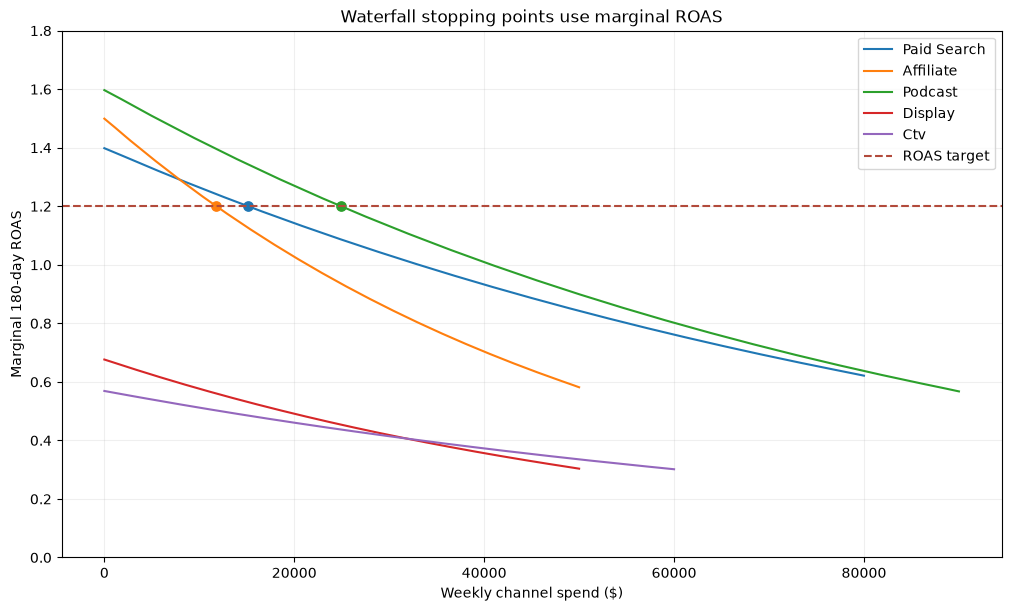

In [4]:
waterfall_spend = {}
for channel, spec in response_assumptions.iterrows():
    grid = np.linspace(0, spec["max_weekly_spend"], 10001)
    marginal = response_models[channel]["marginal_roas"](grid)
    eligible = grid[marginal >= ROAS_TARGET]
    selected = float(eligible[-1]) if len(eligible) else 0.0
    if selected < spec["min_active_spend"]:
        selected = 0.0
    waterfall_spend[channel] = selected

waterfall_allocation = allocation_table(waterfall_spend)
assert waterfall_allocation.loc[
    waterfall_allocation["spend"].gt(0), "marginal_roas"
].min() >= ROAS_TARGET - 0.002
display(waterfall_allocation)
print(f"Emergent weekly portfolio budget: ${waterfall_allocation['spend'].sum():,.0f}")
print(
    "Portfolio 180-day ROAS: "
    f"{waterfall_allocation['revenue_180d'].sum() / waterfall_allocation['spend'].sum():.3f}×"
)

waterfall_figure = Figure(figsize=(10, 6), layout="constrained")
waterfall_ax = waterfall_figure.subplots()
for channel, spec in response_assumptions.iterrows():
    grid = np.linspace(0, spec["max_weekly_spend"], 400)
    waterfall_ax.plot(
        grid, response_models[channel]["marginal_roas"](grid),
        label=channel.replace("_", " ").title(),
    )
    if waterfall_spend[channel] > 0:
        waterfall_ax.scatter(
            waterfall_spend[channel], marginal_roas(channel, waterfall_spend[channel]),
            s=45,
        )
waterfall_ax.axhline(ROAS_TARGET, color="#B24A3B", linestyle="--", label="ROAS target")
waterfall_ax.set(
    title="Waterfall stopping points use marginal ROAS",
    xlabel="Weekly channel spend ($)", ylabel="Marginal 180-day ROAS",
    ylim=(0, 1.8),
)
waterfall_ax.legend()
waterfall_ax.grid(alpha=0.2)
display(waterfall_figure)

## Model 2: Distributed budgeting

The CMO must deploy exactly $60k per week. With a fixed denominator, maximizing portfolio ROAS is equivalent to maximizing total 180-day revenue.

Active channels must:

- receive at least their minimum testable spend,
- stay within their observed historical range, and
- maintain average channel ROAS of at least 1.20×.

Because spend may also be exactly zero, the optimization enumerates possible active-channel sets and solves each continuous allocation with SLSQP. This avoids pretending that a tiny, operationally meaningless allocation is a valid campaign.

In [5]:
def solve_distributed_budget(budget):
    channels = response_assumptions.index.tolist()
    best = None
    for active_count in range(1, len(channels) + 1):
        for active in combinations(channels, active_count):
            lower = response_assumptions.loc[list(active), "min_active_spend"].to_numpy(float)
            upper = response_assumptions.loc[list(active), "max_weekly_spend"].to_numpy(float)
            if lower.sum() > budget or upper.sum() < budget:
                continue
            capacity = upper - lower
            initial = lower + (budget - lower.sum()) * capacity / capacity.sum()

            def objective(values):
                return -sum(revenue(channel, value) for channel, value in zip(active, values))

            constraints = [{"type": "eq", "fun": lambda values: values.sum() - budget}]
            for position, channel in enumerate(active):
                constraints.append({
                    "type": "ineq",
                    "fun": lambda values, position=position, channel=channel: (
                        revenue(channel, values[position])
                        - ROAS_TARGET * values[position]
                    ),
                })
            solution = minimize(
                objective,
                initial,
                method="SLSQP",
                bounds=list(zip(lower, upper)),
                constraints=constraints,
                options={"ftol": 1e-9, "maxiter": 1000},
            )
            if not solution.success:
                continue
            candidate_revenue = -solution.fun
            if best is None or candidate_revenue > best["revenue"]:
                best = {
                    "revenue": candidate_revenue,
                    "active": active,
                    "spend": solution.x,
                    "message": solution.message,
                }
    if best is None:
        raise RuntimeError("No feasible channel allocation satisfies the budget and ROAS constraints.")
    allocation = pd.Series(0.0, index=channels)
    allocation.loc[list(best["active"])] = best["spend"]
    return allocation


distributed_spend = solve_distributed_budget(DISTRIBUTED_BUDGET)
distributed_allocation = allocation_table(distributed_spend)
assert abs(distributed_allocation["spend"].sum() - DISTRIBUTED_BUDGET) < 0.01
assert distributed_allocation.loc[
    distributed_allocation["spend"].gt(0), "average_roas"
].min() >= ROAS_TARGET - 0.001
display(distributed_allocation)
print(
    "Optimized portfolio 180-day ROAS: "
    f"{distributed_allocation['revenue_180d'].sum() / DISTRIBUTED_BUDGET:.3f}×"
)

,spend,revenue_180d,average_roas,marginal_roas
channel,,,,
paid_search,"18,527.718","23,633.813",1.276,1.160
affiliate,"13,598.027","17,987.777",1.323,1.160
podcast,"27,874.255","38,117.423",1.367,1.160
display,0.000,0.000,NaN,0.676
ctv,0.000,0.000,NaN,0.569


Optimized portfolio 180-day ROAS: 1.329×


## Benchmark the optimized allocation

An equal split is simple but ignores both cohort quality and saturation. Here it also directs money to Display and CTV even though their direct-attribution cohorts cannot clear the 1.20× hurdle.

This is an intentionally strict direct-response view. The separate subscription CFO notebook shows how an incrementality-tested CTV halo can justify a different portfolio decision.

,Distributed optimizer,Equal split — all channels,Equal split — qualified channels
channel,,,
paid_search,"18,527.718","12,000.000","20,000.000"
affiliate,"13,598.027","12,000.000","20,000.000"
podcast,"27,874.255","12,000.000","20,000.000"
display,0.000,"12,000.000",0.000
ctv,0.000,"12,000.000",0.000


,revenue_180d,portfolio_roas,channels_below_target
plan,,,
Distributed optimizer,"79,739.013",1.329,0
Equal split — all channels,"63,631.681",1.061,2
Equal split — qualified channels,"78,864.918",1.314,0


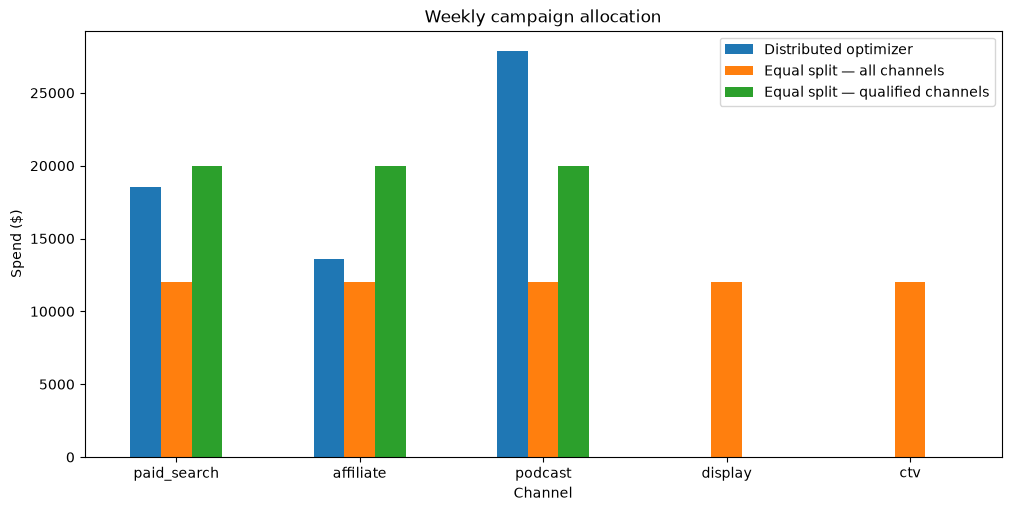

In [6]:
equal_spend = pd.Series(
    DISTRIBUTED_BUDGET / len(response_assumptions),
    index=response_assumptions.index,
)
equal_allocation = allocation_table(equal_spend)

qualified_channels = ["paid_search", "affiliate", "podcast"]
qualified_equal_spend = pd.Series(0.0, index=response_assumptions.index)
qualified_equal_spend.loc[qualified_channels] = DISTRIBUTED_BUDGET / len(qualified_channels)
qualified_equal_allocation = allocation_table(qualified_equal_spend)

allocation_comparison = pd.DataFrame({
    "Distributed optimizer": distributed_allocation["spend"],
    "Equal split — all channels": equal_allocation["spend"],
    "Equal split — qualified channels": qualified_equal_allocation["spend"],
})
display(allocation_comparison)

benchmark = pd.DataFrame([
    {
        "plan": "Distributed optimizer",
        "revenue_180d": distributed_allocation["revenue_180d"].sum(),
        "portfolio_roas": distributed_allocation["revenue_180d"].sum() / DISTRIBUTED_BUDGET,
        "channels_below_target": 0,
    },
    {
        "plan": "Equal split — all channels",
        "revenue_180d": equal_allocation["revenue_180d"].sum(),
        "portfolio_roas": equal_allocation["revenue_180d"].sum() / DISTRIBUTED_BUDGET,
        "channels_below_target": int((equal_allocation["average_roas"] < ROAS_TARGET).sum()),
    },
    {
        "plan": "Equal split — qualified channels",
        "revenue_180d": qualified_equal_allocation["revenue_180d"].sum(),
        "portfolio_roas": qualified_equal_allocation["revenue_180d"].sum() / DISTRIBUTED_BUDGET,
        "channels_below_target": int(
            (qualified_equal_allocation.loc[qualified_channels, "average_roas"] < ROAS_TARGET).sum()
        ),
    },
]).set_index("plan")
display(benchmark)

allocation_figure = Figure(figsize=(10, 5), layout="constrained")
allocation_ax = allocation_figure.subplots()
allocation_comparison.plot(kind="bar", ax=allocation_ax)
allocation_ax.set(title="Weekly campaign allocation", xlabel="Channel", ylabel="Spend ($)")
allocation_ax.tick_params(axis="x", rotation=0)
display(allocation_figure)

## Push the chosen plans back through Theseus

The response optimizer decides spend. Theseus remains the financial source of truth: each allocation is converted into channel cohorts, broadcast over 180 days, and compared at common maturity checkpoints.

,spend,30d_roas,90d_roas,180d_roas,180d_revenue,cash_at_risk
plan,,,,,,
Waterfall,"51,875.000",0.288,0.782,1.352,"70,153.499","51,366.536"
Distributed optimizer,"60,000.000",0.284,0.768,1.329,"79,739.108","59,421.441"
Equal split — all,"60,000.000",0.248,0.642,1.061,"63,631.513","59,481.406"
Equal split — qualified,"60,000.000",0.284,0.765,1.314,"78,864.959","59,420.341"


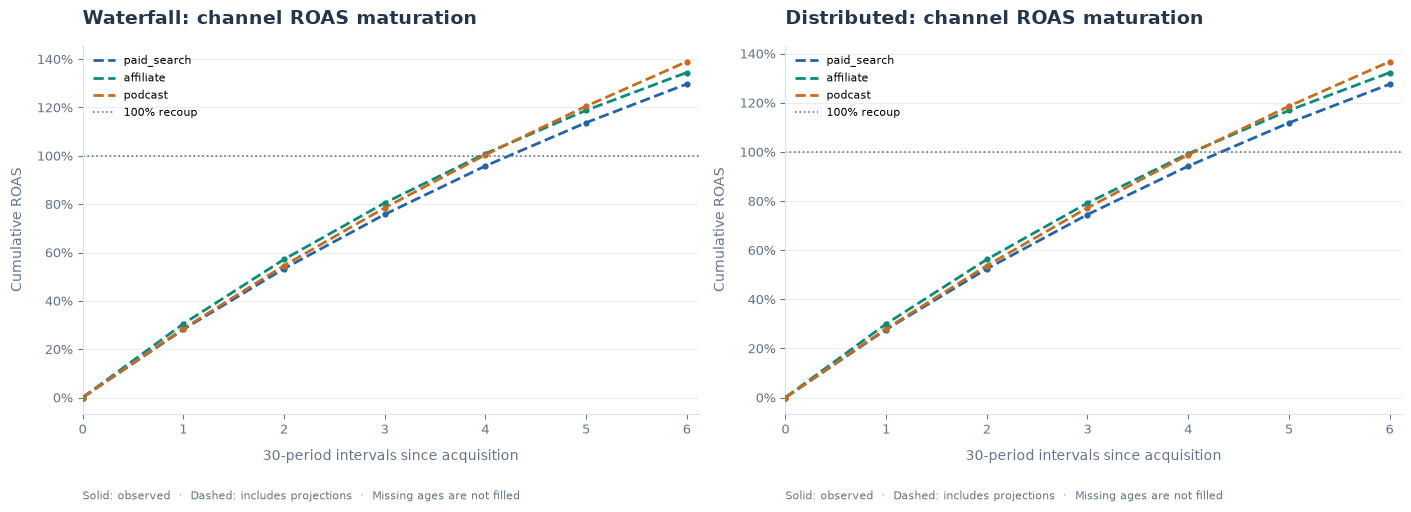

In [7]:
def forecast_allocation(spend_by_channel):
    cohort_rows, spend_rows = [], []
    for channel, spend in spend_by_channel.items():
        if spend <= 0.01:
            continue
        spec = response_assumptions.loc[channel]
        population = spec["saturation_subscribers"] * (
            1 - np.exp(-spend / (spec["cac"] * spec["saturation_subscribers"]))
        )
        cohort_rows.append({
            "cohort_id": channel,
            "acquisition_period": 0,
            "population": population,
            "curve_id": spec["curve_id"],
            "channel": channel,
        })
        spend_rows.append({"period": 0, "cohort_id": channel, "amount": spend})
    return tg.forecast(
        pd.DataFrame(cohort_rows), curves,
        acquisition_spend=pd.DataFrame(spend_rows),
        as_of=0, forecast_end=REVENUE_WINDOW - 1, start=0,
    )


waterfall_result = forecast_allocation(pd.Series(waterfall_spend))
distributed_result = forecast_allocation(distributed_spend)
equal_result = forecast_allocation(equal_spend)
qualified_equal_result = forecast_allocation(qualified_equal_spend)


def maturity_row(name, result):
    timeline = result.timeline()
    spend = timeline["acquisition_spend"].sum()
    cumulative_revenue = timeline["revenue"].cumsum()
    return {
        "plan": name,
        "spend": spend,
        "30d_roas": cumulative_revenue.iloc[29] / spend,
        "90d_roas": cumulative_revenue.iloc[89] / spend,
        "180d_roas": cumulative_revenue.iloc[179] / spend,
        "180d_revenue": cumulative_revenue.iloc[179],
        "cash_at_risk": result.metrics().iloc[0]["cash_at_risk"],
    }


maturity = pd.DataFrame([
    maturity_row("Waterfall", waterfall_result),
    maturity_row("Distributed optimizer", distributed_result),
    maturity_row("Equal split — all", equal_result),
    maturity_row("Equal split — qualified", qualified_equal_result),
]).set_index("plan")
display(maturity)

progression_figure = Figure(figsize=(14, 5), layout="constrained")
waterfall_ax, distributed_ax = progression_figure.subplots(1, 2)
waterfall_result.plot.cohort_progression(
    interval=30, ax=waterfall_ax, title="Waterfall: channel ROAS maturation"
)
distributed_result.plot.cohort_progression(
    interval=30, ax=distributed_ax, title="Distributed: channel ROAS maturation"
)
display(progression_figure)

## CMO interpretation

- **Waterfall** answers “How much can I spend while the next dollar still clears my hurdle?” Its total budget emerges from the channel response curves.
- **Distributed** answers “Given a fixed budget, where should each dollar go?” It equalizes marginal opportunity subject to the active-channel ROAS constraints and observed scale limits.
- A fixed-budget portfolio can spend beyond the Waterfall stopping point because the Distributed model constrains **average** channel ROAS, while Waterfall stops on **marginal** ROAS. Those are different operating policies, not contradictory answers.
- Cohort maturity matters. A 30-day dashboard can reject campaigns that clear the 180-day hurdle; the maturity table makes that tradeoff explicit.
- Historical response is not destiny. Before production use, add uncertainty bands, out-of-sample validation, auction and creative regime changes, incrementality estimates, and guardrails against extrapolation beyond observed spend.